# Model 01: Sales Revenue Forecasting
### College Data Mining & DWDM Laboratory Submission
**Algorithm:** Linear Regression  
**Problem Type:** Time-Series Regression  
**Key Concepts Demonstrated:**
- Syllabus-aligned algorithm implementation
- Data preprocessing & descriptive statistics
- Model training, hyperparameter tuning & evaluation
- Joblib model serialization and sample inference


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Ensure parent directory is in path
sys.path.append(os.path.abspath(".."))
from preprocessing.preprocess import load_dataset, clean_and_impute

# Load and clean dataset
df = load_dataset()
df_clean = clean_and_impute(df)
print(f"Dataset ready: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
df_clean.head(3)


Dataset ready: 1000 rows, 30 columns


,date,day_of_week,is_weekend,product_name,category,price,discount,previous_day_sales,sales_7_day_average,sales_30_day_average,...,sales_90_day,turnover_rate,days_since_last_sale,category_label,inventory_status,business_activity,total_expense,expense_3_month_average,average_order_value,profit
0,2024-01-01,Monday,0,Laundry Detergent 1kg,Household,210.0,10.43,3599.34,3599.34,3599.34,...,205357.08,3.62,12,MEDIUM_DEMAND,RESTOCK,14.87,3044.67,3044.67,97.28,-275.43
1,2024-01-02,Tuesday,0,Basmati Rice 5kg,Grocery,450.0,2.96,3599.34,3656.81,3656.81,...,316258.19,3.77,1,MEDIUM_DEMAND,RESTOCK,15.39,3100.65,3072.66,95.24,-358.75
2,2024-01-03,Wednesday,0,Organic Honey 500g,Grocery,280.0,6.88,3714.28,3750.13,3750.13,...,159407.77,5.20,0,MEDIUM_DEMAND,RESTOCK,12.33,3445.75,3197.02,115.79,-448.90


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Chronological split to prevent data leakage
feature_cols = ["previous_day_sales", "sales_7_day_average", "sales_30_day_average", "invoice_count", "quantity_sold", "discount"]
target_col = "revenue"
split_idx = int(len(df_clean) * 0.8)

X_train, y_train = df_clean.iloc[:split_idx][feature_cols].values, df_clean.iloc[:split_idx][target_col].values
X_test, y_test = df_clean.iloc[split_idx:][feature_cols].values, df_clean.iloc[split_idx:][target_col].values

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Evaluation Metrics:")
print(f"  MAE:  Rs. {mean_absolute_error(y_test, y_pred):.2f}")
print(f"  RMSE: Rs. {root_mean_squared_error(y_test, y_pred):.2f}")
print(f"  R²:   {r2_score(y_test, y_pred):.4f}")


Evaluation Metrics:
  MAE:  Rs. 316.75
  RMSE: Rs. 411.43
  R²:   0.6517


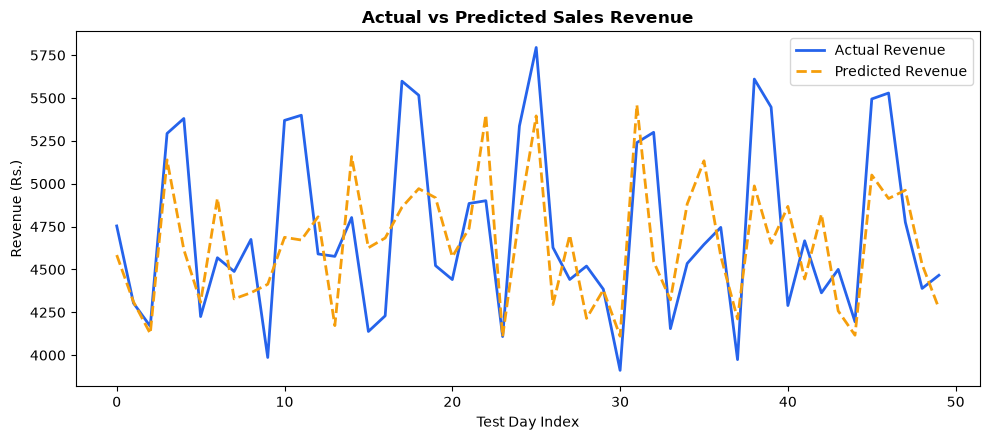

In [3]:
# Visualization: Actual vs Predicted Sales
plt.figure(figsize=(10, 4.5))
plt.plot(y_test[:50], label='Actual Revenue', color='#2563eb', lw=2)
plt.plot(y_pred[:50], label='Predicted Revenue', color='#f59e0b', linestyle='--', lw=2)
plt.title("Actual vs Predicted Sales Revenue", fontsize=12, fontweight='bold')
plt.xlabel("Test Day Index")
plt.ylabel("Revenue (Rs.)")
plt.legend()
plt.tight_layout()
plt.show()


In [4]:
# Model Persistence using Joblib
joblib.dump(model, "../models/sales_model.joblib")
del model
loaded_model = joblib.load("../models/sales_model.joblib")

sample = np.array([[4000.0, 4300.0, 4100.0, 35, 120, 5.0]])
print(f"Reloaded Model Prediction for Sample: Rs. {loaded_model.predict(sample)[0]:.2f}")


Reloaded Model Prediction for Sample: Rs. 4014.72
